# Belebele E4B 8-bit: investigate saved mistakes

Inspect only the completed **E4B INT8** run in `results/belebele-e4b-8bit-full`. Counts, response summaries, and illustrative cases are computed from this run's saved predictions. No earlier run or fixed historical case annotations are used.

**No new inference, score changes, or model-weight loading.** Default cells use saved results plus pinned dataset text already in the Hugging Face cache. The optional input preview reconstructs one selected example on CPU using its cached processor; it is disabled by default.

Run all cells using the project `.venv` kernel. This notebook is saved clean: charts appear when cells run. Clear outputs before saving/sharing.


In [1]:
from pathlib import Path
from html import escape
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from rendering_eval.error_analysis import ErrorExplorer, plot_error_patterns
from rendering_eval.reporting import LANGUAGE_NAMES

RESULTS_DIR = Path("results/belebele-e4b-8bit-full")
explorer = ErrorExplorer(RESULTS_DIR)
if len(explorer.rows) != 2 * len(explorer.manifest["selection"]):
    raise ValueError("Select a completed evaluation before using this notebook.")
diagnosis = explorer.diagnosis()
CASE_STUDIES = explorer.representative_cases(limit=8)
print("Run:", RESULTS_DIR)
print("Model:", explorer.manifest["experiment"]["model_id"], "—",
      explorer.manifest["experiment"]["quantization"])
plot_handles = []
def show_plot(figure):
    plot_handles.append(display(figure, display_id=True))
    plt.close(figure)

print(f"{diagnosis['image_errors']:,} image errors: "
      f"{diagnosis['valid_wrong_image']:,} valid wrong choices + {diagnosis['invalid_image']} invalid responses")
print(f"If EVERY invalid image response became correct: "
      f"{diagnosis['image_accuracy_pct']:.2f}% → {diagnosis['all_invalid_correct_upper_bound_pct']:.2f}% "
      f"(+{diagnosis['max_gain_from_invalid_pp']:.2f} points at most).")

Run: results/belebele-e4b-8bit-full
Model: google/gemma-4-E4B-it — bitsandbytes-int8
6,995 image errors: 6,857 valid wrong choices + 138 invalid responses
If EVERY invalid image response became correct: 35.23% → 36.51% (+1.28 points at most).


## Invalid responses and the answer budget

The instruction asks for one A–D letter. Generation is **greedy but unconstrained**: it can emit words as well as A–D. The scorer accepts a single letter, allowing case differences, `(A)`, or `A.`. It does not infer an answer from prose. Invalid or truncated answers remain incorrect.

The next cell counts the current run's invalid responses by language, observable behavior, raw response, and generated-token count. It also shows how often the corresponding text answer was correct. These descriptions summarize emitted text; a request for a passage does not itself establish missing input.

Thinking was disabled in the saved prompt configuration. The saved outputs cannot reveal whether a longer answer budget would eventually yield a correct answer. Extending the budget or forcing A–D decoding would be a separate experiment.


In [2]:
invalid_all = pd.DataFrame(diagnosis["invalid_details"])
invalid = invalid_all[invalid_all["mode"] == "image"].copy() if not invalid_all.empty else invalid_all
SHOW_ALL_INVALID_RESPONSES = False  # Opt in to the full row-level table.
if invalid.empty:
    print("No invalid image responses in this run.")
else:
    display(invalid.groupby("behavior").size().rename("Count").to_frame())
    summary = invalid.groupby("language").agg(
        Invalid=("sample_id", "size"),
        Same_language_text_correct=("text_correct", "sum"),
        English_image_correct=("english_image_correct", "sum"),
        Generated_tokens_min=("generated_tokens", "min"),
        Generated_tokens_max=("generated_tokens", "max"),
    ).rename(index=LANGUAGE_NAMES)
    display(summary)
    print(f"Same-language text correct: {invalid.text_correct.sum()}/{len(invalid)} invalid-image cases.")
    print(f"Distinct invalid image response strings: {invalid.raw_response.nunique()}")
    display(invalid.groupby("raw_response", sort=False).size().rename("Count").to_frame().style.set_properties(
        **{"white-space": "pre-wrap", "text-align": "left"}))
    if SHOW_ALL_INVALID_RESPONSES:
        display(invalid[["sample_id", "language", "gold", "raw_response", "behavior", "generated_tokens",
                         "text_correct", "english_image_correct"]].style.format(escape="html").set_properties(
            **{"white-space": "pre-wrap", "text-align": "left"}))


,Count
behavior,
claims incomplete input; token limit,1
prose instead of a choice; token limit,105
requests passage; token limit,32


,Invalid,Same_language_text_correct,English_image_correct,Generated_tokens_min,Generated_tokens_max
language,,,,,
Arabic (MSA),3,2,0,16,16
English,1,1,0,16,16
Khmer,3,2,2,16,16
Burmese,131,100,104,16,16


Same-language text correct: 105/138 invalid-image cases.
Distinct invalid image response strings: 35


,Count
raw_response,
The provided text is in Burmese and appears to be a passage from a religious or,16
The user has provided an image containing a passage in Burmese script and a multiple-,23
The provided text is in Burmese and appears to be a passage followed by a multiple,10
The provided text is in the Burmese language. To answer the multiple-choice question,2
I need the passage and the multiple-choice question to answer. Please provide them,24
The user has provided a passage in Burmese script and a multiple-choice question format,3
The provided text is in Khmer and appears to be a multiple-choice question based,2
The provided text is in Burmese and appears to be a passage followed by multiple-,5
"The user has provided an image containing a passage in Burmese script, followed by a",2


## Valid wrong choices and answer-label patterns

The following summary separates valid wrong image answers from invalid ones using the current run. The heatmaps condition on the correct answer label, and the confusion matrices show where predictions go. This reveals label-dependent behavior without confusing response-format errors with incorrect choices.

Correct-label groups contain different questions. Answer-order permutations would be needed to establish a causal position effect.


In [3]:
share = 100 * diagnosis["valid_wrong_image"] / diagnosis["image_errors"] if diagnosis["image_errors"] else 0
print(f"Valid wrong choices account for {share:.2f}% of image errors in this run.")
show_plot(plot_error_patterns(diagnosis))
errors = pd.DataFrame(diagnosis["language_errors"])
errors["Language"] = errors.language.map(LANGUAGE_NAMES)
errors["Dominant_choice_share_of_valid_errors_%"] = (
    100 * errors.wrong_image_most_common_choice_n / errors.image_valid_wrong)
display(errors[["Language", "text_wrong", "image_valid_wrong", "image_invalid",
                "wrong_image_most_common_choice", "wrong_image_most_common_choice_n",
                "Dominant_choice_share_of_valid_errors_%"]].round(2))

Valid wrong choices account for 98.03% of image errors in this run.


'Display cleared; rerun its cell to inspect again.'

,Language,text_wrong,image_valid_wrong,image_invalid,wrong_image_most_common_choice,wrong_image_most_common_choice_n,Dominant_choice_share_of_valid_errors_%
0,English,120,253,1,A,118,46.64
1,Russian,133,514,0,A,284,55.25
2,Arabic (MSA),176,632,3,B,244,38.61
3,Hindi,248,600,0,A,274,45.67
4,Bengali,211,661,0,A,321,48.56
5,Telugu,277,692,0,A,459,66.33
6,Thai,218,638,0,A,424,66.46
7,Khmer,244,679,3,A,594,87.48
8,Burmese,252,582,131,D,289,49.66
9,Chinese (simplified),179,539,0,A,293,54.36


## Page dimensions and invalid responses

Compare invalid and valid image responses within each language using saved rendering and processor metadata. Document height and the nominal post-resize font size are descriptive proxies; they do not establish legibility, input omission, or a failure mechanism.

No visual inspection or rerendering is performed by these default cells. The optional preview below can reconstruct the selected case from this run on CPU, and checks its dimensions against the saved metadata. A model's statement that an input is incomplete is not an input audit.


In [4]:
comparison = pd.DataFrame(diagnosis["invalid_comparisons"])
comparison.insert(0, "Language", comparison.language.map(LANGUAGE_NAMES))
display(comparison.drop(columns="language").round(2))

,Language,invalid_n,valid_n,invalid_height_median,valid_height_median,invalid_text_correct,invalid_nominal_size_median,valid_nominal_size_median
0,English,1,899,577.0,676.0,1,23.96,22.15
1,Arabic (MSA),3,897,941.0,941.0,2,19.12,19.12
2,Khmer,3,897,577.0,682.0,2,23.96,21.96
3,Burmese,131,769,1135.0,1294.0,100,16.88,15.75


## Illustrative cases selected from this run

Cases are selected deterministically from the current saved predictions: invalid-image examples across affected languages, followed by contrasting text-only, image-only, both-wrong, and both-correct outcomes where available. They are illustrative, **not a random sample**.

Each card includes the pinned English reference and the saved responses in both languages and modalities. Notes describe the current saved scores and observable response format; they do not reuse annotations from another run. Source records are verified against manifest hashes and saved answer labels before display. Gold answers appear only in analysis.


In [5]:
cards = []
for study in CASE_STUDIES:
    detail = explorer.case(study["sample_id"], study["language"])
    reference = detail["english"] or detail["example"]
    table = pd.DataFrame(detail["comparison"])[
        ["language", "mode", "gold", "raw_response", "correct", "valid", "truncated"]]
    cards.append(
        f"<details style='margin:12px 0;padding:10px;border:1px solid #ccc'>"
        f"<summary><b>{escape(study['title'])}</b></summary>"
        f"<p>{escape(study['note'])}</p>"
        f"<p><b>English reference:</b></p><pre style='white-space:pre-wrap'>{escape(reference.task_text())}</pre>"
        f"<p>Gold: <b>{reference.answer}</b></p>" + table.to_html(index=False, escape=True) +
        f"<p>Sample ID: <code>{study['sample_id']}</code></p></details>"
    )
display(HTML("".join(cards)))

language,mode,gold,raw_response,correct,valid,truncated
eng_Latn,text,B,B,True,True,False
eng_Latn,image,B,"The provided text states: ""The band canceled the show at Maui's War",False,False,True
language,mode,gold,raw_response,correct,valid,truncated
arb_Arab,text,A,A,True,True,False
arb_Arab,image,A,"The provided text is a passage in Arabic, but it is incomplete as it ends",False,False,True
eng_Latn,text,A,A,True,True,False
eng_Latn,image,A,B,False,True,False
language,mode,gold,raw_response,correct,valid,truncated
khm_Khmr,text,D,D,True,True,False
khm_Khmr,image,D,The provided text is in Khmer and appears to be a passage followed by a multiple,False,False,True


## Browse a selected case or any saved outcome

Choose a current-run illustrative case, or set `CASE_SOURCE = "browse"` and filter by language/outcome. Outcomes are `invalid image`, `text only`, `image only`, `both wrong`, and `both correct`. Browsing is deterministic by sample ID; no inference runs. Change the settings and rerun this cell, then the source-display cell.


In [6]:
CASE_SOURCE = "curated"  # "curated" or "browse"
CURATED_CASE = 0
BROWSE_LANGUAGE = "mya_Mymr"
BROWSE_OUTCOME = "invalid image"
BROWSE_INDEX = 0

if CASE_SOURCE == "curated":
    if not 0 <= CURATED_CASE < len(CASE_STUDIES):
        raise ValueError(f"CURATED_CASE must be between 0 and {len(CASE_STUDIES) - 1}")
    selected = CASE_STUDIES[CURATED_CASE]
    SAMPLE_ID, LANGUAGE = selected["sample_id"], selected["language"]
    display(Markdown(f"**{selected['title']}**  \n{selected['note']}"))
elif CASE_SOURCE == "browse":
    candidates = explorer.pairs[(explorer.pairs.language == BROWSE_LANGUAGE) &
                               (explorer.pairs.outcome == BROWSE_OUTCOME)].sort_values("sample_id")
    print(f"{len(candidates)} matching cases; selected index {BROWSE_INDEX}")
    if not 0 <= BROWSE_INDEX < len(candidates):
        raise ValueError("BROWSE_INDEX is outside the available cases")
    row = candidates.iloc[BROWSE_INDEX]
    SAMPLE_ID, LANGUAGE = row.sample_id, row.language
    display(candidates[["sample_id", "answer", "text_predicted", "image_predicted", "render_height"]].head(20))
else:
    raise ValueError("CASE_SOURCE must be curated or browse")
print("Selected:", LANGUAGE, SAMPLE_ID)

**English: invalid image**  
Selected from the current run. Gold B; text correct; image incorrect. Image response: prose instead of a choice; token limit.

Selected: eng_Latn 0551f4693fd3b1b66f2ea83335915c29def8da837cb11c49e740a88ba6e61439


In [7]:
detail = explorer.case(SAMPLE_ID, LANGUAGE)
example = detail["example"]
print("Gold:", example.answer, "—", example.choices["ABCD".index(example.answer)])
display(pd.DataFrame(detail["comparison"]).style.format(escape="html").set_properties(
    **{"white-space": "pre-wrap", "text-align": "left"}))
display(HTML(f"<h4>Actual {escape(LANGUAGE)} input text</h4>"
             f"<pre dir='auto' style='white-space:pre-wrap;font-size:16px'>{escape(example.task_text())}</pre>"))
if detail["english"] is not None and LANGUAGE != "eng_Latn":
    display(HTML("<details><summary>Aligned English reference</summary>"
                 f"<pre style='white-space:pre-wrap'>{escape(detail['english'].task_text())}</pre></details>"))

Gold: B — The management company


,language,mode,gold,raw_response,correct,valid,truncated,generated_tokens,source_height,processed_width,processed_height
0,eng_Latn,text,B,B,True,True,False,2,nan,nan,nan
1,eng_Latn,image,B,"The provided text states: ""The band canceled the show at Maui's War",False,False,True,16,577.000000,1056.000000,576.000000


## Optional: original rendering and actual processor input

Set the flag below to `True` to inspect **one selected case**. This uses the cached processor on CPU, with no model weights or inference. Fonts must be available from the evaluation setup. The processor comes strictly from the local cache. Images are rendered on demand, displayed, and released; rerunning replaces the previous case display.

Compare this with the model's claim about missing/incomplete text. Use the original overview notebook for broad language statistics. No chart or benchmark image files are saved.

'Previous case cleared.'

Rendering and processor metadata match the evaluated example.


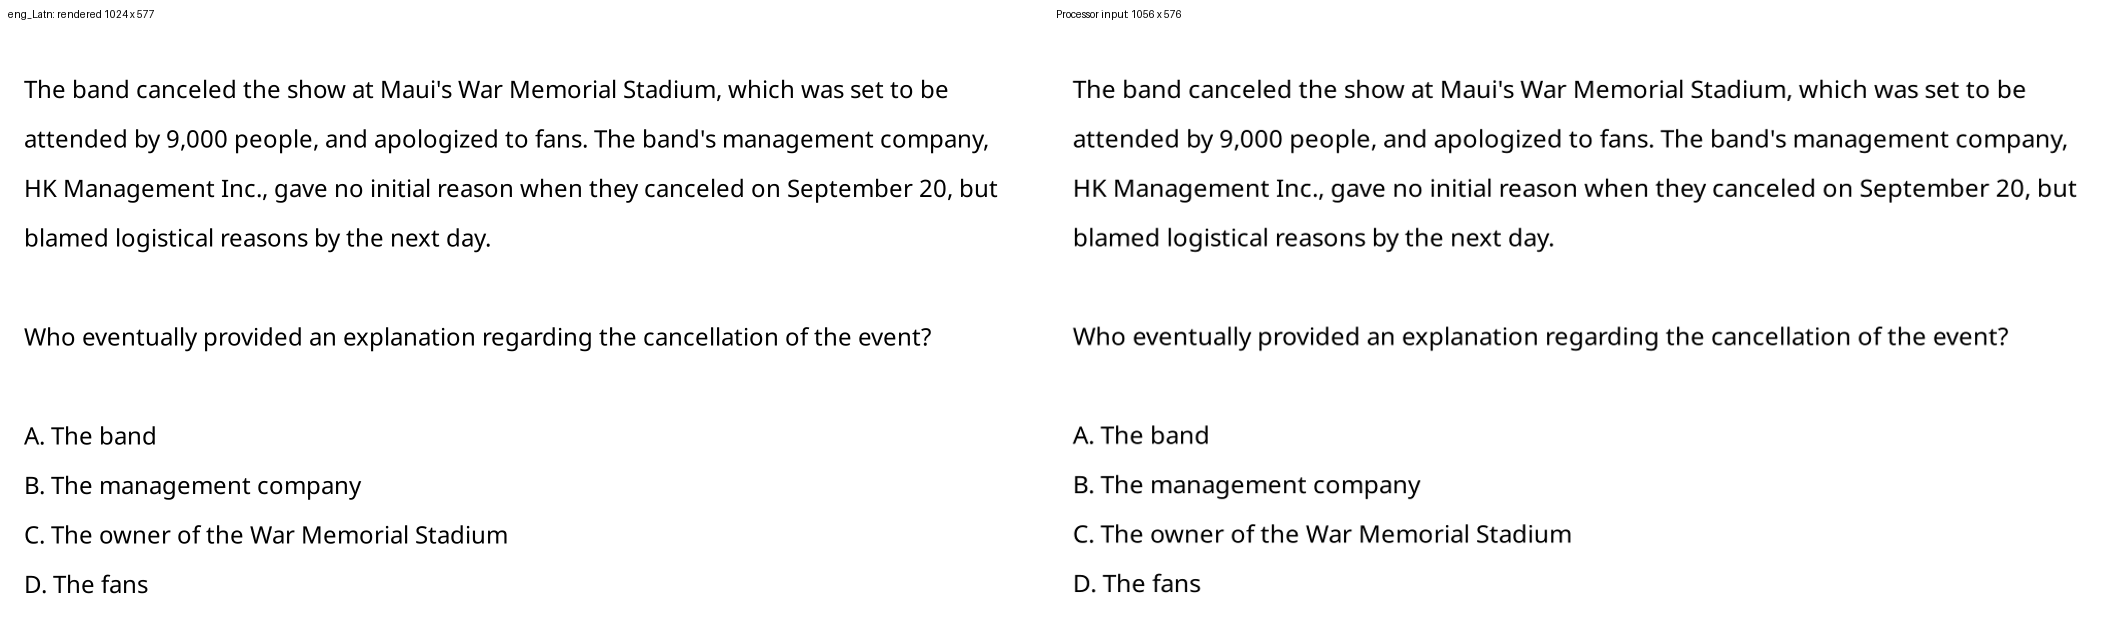

Rendering and processor metadata match the evaluated example.


In [13]:
SHOW_INPUT_PREVIEW = True  # Opt in to the processor-only, in-memory preview.
if SHOW_INPUT_PREVIEW:
    from transformers import AutoProcessor
    from rendering_eval.rendering import DocumentRenderer
    from rendering_eval.preview import preview_example
    cfg = explorer.config()
    processor_key = (cfg.model_id, cfg.model_revision, cfg.max_soft_tokens)
    if globals().get("case_processor_key") != processor_key:
        case_processor = AutoProcessor.from_pretrained(
            cfg.model_id, revision=cfg.model_revision, local_files_only=True)
        case_processor.image_processor.max_soft_tokens = cfg.max_soft_tokens
        case_renderer = DocumentRenderer(cfg)
        case_processor_key = processor_key
    if "case_preview_handle" in globals():
        case_preview_handle.update("Previous case cleared.")
    case_preview_handle, metadata = preview_example(
        cfg, explorer.sources()[SAMPLE_ID, LANGUAGE], renderer=case_renderer, processor=case_processor)
    plot_handles.append(case_preview_handle)
    saved = explorer.index[SAMPLE_ID, LANGUAGE, "image"]
    assert all(metadata[k] == value for k, value in saved["rendering"].items())
    assert all(metadata[k] == saved["inference"][k] for k in (
        "processed_width", "processed_height", "real_patches", "padded_patches", "soft_tokens"))
    print("Rendering and processor metadata match the evaluated example.")
else:
    print("Input preview disabled; default analysis loads no PyTorch or model.")

## What the current run establishes

The counts and plots above distinguish invalid responses, valid wrong choices, and paired successes. Raw responses document what the model emitted; neither those strings nor page dimensions isolate visual reading, instruction following, semantic reasoning, or quantization as the cause.

The invalid-response upper bound assumes every invalid answer could become correct. It is not a rescore, a prediction of a longer-token-budget experiment, or a reason to discard invalid cases. All original scores remain unchanged.

Useful separate experiments include increasing the answer budget, comparing unconstrained with forced A–D decoding, permuting answer order, or increasing the image-token budget on the same IDs. None runs here, and this notebook makes no comparison with another run.

Before sharing, clear outputs using the notebook menu or run:

```bash
.venv/bin/python scripts/clean_notebook.py Belebele_errors.ipynb
```

The next cell can replace live plot/preview displays with text. See [README](README.md) for provenance and attribution.


In [ ]:
CLEAR_PLOTS = False  # Set True before saving a clean notebook.
if CLEAR_PLOTS:
    for handle in plot_handles:
        handle.update("Display cleared; rerun its cell to inspect again.")
    plot_handles.clear()
    plt.close("all")